# Course Code: DT8013
# Course Name: Data Mining
# Lab Session: Anomaly Detection

### This lab is due on the 07/10/2026 at 23:59
### Save the notebook: 'yourname_lab_anomaly_detection.ipynb' and submit by the due date.



### Purpose of the Lab:
- Gain practical experience in applying anomaly detection techniques to real world data. 
- Analyze and evaluate the results of anomaly detection.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
from scipy.spatial.distance import cdist
pd.set_option("display.max_columns",100)


## Anomaly Detection In High Dimensions
In this lab, we will investigate anomaly detection for high-dimensional data.

<div class='alert alert-block alert-success' style="font-weight:bolder">

### Task 1: When does “distance” stop working? (Optional)

- Generate synthetic Gaussian data with different dimensionalities (d=2, 10, 100, 1000).
- Compute nearest and farthest neighbour distances for random points.
- Plot how the ratio between nearest and farthest changes with d.
- Question: Why does this make distance-based anomaly detection algorithms unreliable in high dimensions?
</div>

Dimension = 2: ratio = 0.0202
Dimension = 10: ratio = 0.2806
Dimension = 100: ratio = 0.6910
Dimension = 1000: ratio = 0.8901


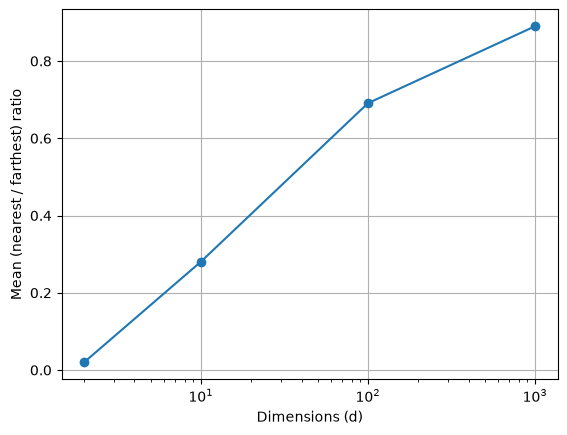

In [ ]:
### Your Code Here
dimensions = [2,10,100,1000]
no_of_points = 500
ratios = [] 

rng = np.random.default_rng(None) 

for d in dimensions:
    # 1. Generate the Gausian random Data  points 
    X = rng.normal(0,1,size=(no_of_points, d))

    # 2. Select the random points  
    idx = rng.choice(no_of_points, size=50, replace=False)
    
    # 3. Calculate the distances of those selected points from all
    D = cdist(X[idx], X) # (50, 500)

    # 4. Remove self distance 
    D[np.arange(len(idx)), idx] = np.nan

    # 5. Compute the nearest and farthest distance, axis = 1 -> across row 
    D_Nearest = np.nanmin(D, axis=1)
    D_Farthest = np.nanmax(D, axis=1)

    # 6. Find ratios and store 
    ratio = np.mean(D_Nearest/D_Farthest)
    ratios.append(ratio)

    print(f"Dimension = {d}: ratio = {ratio:.4f}")

# 7. Plot the trend
plt.plot(dimensions, ratios, marker='o')
plt.xscale('log')
plt.xlabel('Dimensions (d)')
plt.ylabel('Mean (nearest / farthest) ratio')
plt.grid(True)
plt.show()



**Answers**
The plot shows that the ratio of nearest to farthest neighbor distance increases from 0.02 at d=2 to 0.89 at d=1000. This means as the dimension increases the ratio approaches to 1, meaning nearest and farthest neighbors are at a same distance. 

This goes against the analogy of Distance-based anomaly detectors algorithm such as kNN and LOF, which considers distant neighbors as an anomaly. Thus with higher dimensions, the contrast between nearest and farthest vanishes making the ranking unreliable and filled with noises.

## Data overview

This dataset contains information on organisms studied in a laboratory. Each variable corresponds to a aspecific attribute of the organism.

In [22]:
data=pd.read_csv('organisms.csv')
data.head()

,UUA,UUG,CUU,CUC,CUA,CUG,AUU,AUC,AUA,AUG,GUU,GUC,GUA,GUG,GCU,GCC,GCA,GCG,CCU,CCC,CCA,CCG,UGG,GGU,GGC,GGA,GGG,UCU,UCC,UCA,UCG,AGU,AGC,ACU,ACC,ACA,ACG,UAU,UAC,CAA,CAG,AAU,AAC,UGU,UGC,CAU,CAC,AAA,AAG,CGU,CGC,CGA,CGG,AGA,AGG,GAU,GAC,GAA,GAG,UAA,UAG,UGA
0,0.00050,0.00351,0.01203,0.03208,0.00100,0.04010,0.00551,0.02005,0.00752,0.02506,0.01103,0.04110,0.00902,0.03308,0.01003,0.05013,0.01554,0.01103,0.02356,0.03208,0.01203,0.00501,0.01003,0.01203,0.03158,0.01905,0.02456,0.01353,0.02155,0.00251,0.00652,0.00150,0.01554,0.00501,0.02105,0.00902,0.01053,0.00501,0.02256,0.00301,0.03108,0.00401,0.02607,0.00251,0.01153,0.00501,0.02356,0.01053,0.03860,0.00401,0.00702,0.00401,0.00451,0.01303,0.03559,0.01003,0.04612,0.01203,0.04361,0.00251,0.00050,0.00000
1,0.00068,0.00678,0.00407,0.02849,0.00204,0.04410,0.01153,0.02510,0.00882,0.03324,0.00814,0.04071,0.00814,0.03256,0.01085,0.04885,0.01221,0.01357,0.00678,0.02714,0.01221,0.00407,0.01425,0.01221,0.01967,0.02239,0.01289,0.02103,0.01493,0.00407,0.00475,0.00068,0.02035,0.00950,0.02782,0.01425,0.00611,0.00475,0.02917,0.00407,0.02374,0.00882,0.02917,0.00271,0.01628,0.00204,0.01967,0.00543,0.03392,0.00136,0.00678,0.00136,0.00136,0.01696,0.03596,0.01221,0.04545,0.01560,0.04410,0.00271,0.00068,0.00000
2,0.01357,0.01543,0.00782,0.01111,0.01028,0.01193,0.02283,0.01604,0.01316,0.02180,0.01625,0.01872,0.01213,0.01070,0.02406,0.01234,0.01440,0.00514,0.01604,0.01460,0.02098,0.01070,0.01728,0.01851,0.00864,0.01172,0.01892,0.01933,0.01419,0.01296,0.00967,0.01337,0.01337,0.01851,0.01131,0.01419,0.01090,0.02612,0.01275,0.01522,0.02365,0.02962,0.01789,0.01625,0.01234,0.01604,0.01687,0.02077,0.03949,0.00864,0.00596,0.00926,0.00596,0.01974,0.02489,0.03126,0.02036,0.02242,0.02468,0.00391,0.00000,0.00144
3,0.01619,0.00992,0.01567,0.01358,0.00940,0.01723,0.02402,0.02245,0.02507,0.02924,0.02089,0.02141,0.01723,0.01932,0.02141,0.00679,0.02245,0.00522,0.01358,0.00418,0.01410,0.00574,0.01201,0.00992,0.00366,0.02402,0.02663,0.02872,0.00992,0.02350,0.00522,0.01619,0.00836,0.02037,0.01358,0.02089,0.00731,0.02141,0.00888,0.01567,0.01253,0.02298,0.01358,0.00992,0.00888,0.00783,0.00679,0.03133,0.04282,0.00627,0.00261,0.00261,0.00366,0.01410,0.01671,0.03760,0.01932,0.03029,0.03446,0.00261,0.00157,0.00000
4,0.00767,0.03679,0.01380,0.00548,0.00473,0.02076,0.02716,0.00867,0.01310,0.02773,0.02803,0.00508,0.00920,0.02965,0.02878,0.00574,0.01572,0.01577,0.01007,0.00508,0.00604,0.00679,0.01205,0.03127,0.00775,0.00959,0.00797,0.02006,0.00359,0.00933,0.01191,0.01616,0.00788,0.02593,0.00854,0.01200,0.02098,0.02089,0.01367,0.01502,0.01809,0.02738,0.01796,0.01082,0.00705,0.01174,0.00858,0.03408,0.03964,0.00950,0.00429,0.00578,0.00604,0.01494,0.01734,0.04148,0.02483,0.03359,0.03679,0.00000,0.00044,0.00131


<div class='alert alert-block alert-success' style="font-weight:bolder">

### Task 2: Data Preprocessing (1pt)

Your first task is to assess whether the data requires further preprocessing and to execute that if necessary.

</div>

In [34]:
### YOUR CODE HERE

## Checking the data structure, missing values, and dulicates 
print(data.shape)
print("\nColumn dtypes:\n", data.dtypes.value_counts())
non_numeric = data.select_dtypes(exclude=[np.number]).columns.tolist()
print("Non-numeric columns:", non_numeric)


# Missing values
print("Missing Values:",data.isna().sum().sum()) #see the missing values

# Duplicate Values 
print("\nDuplicated:",data.duplicated().sum())

# Feature matrix: numeric columns only , 
X_df = data.select_dtypes(include=[np.number])
print("\nFeature matrix shape:", X_df.shape) # no id col


# Ranges and distributions
print('Range and Distribution:\n')
display(data.describe().T)


(13028, 62)

Column dtypes:
 float64    62
Name: count, dtype: int64
Non-numeric columns: []
Missing Values: 0

Duplicated: 40

Feature matrix shape: (13028, 62)
Range and Distribution:



,count,mean,std,min,25%,50%,75%,max
UUA,13028.0,0.020637,0.020709,0.0,0.005610,0.015260,0.029485,0.15133
UUG,13028.0,0.014104,0.009280,0.0,0.007108,0.013360,0.019810,0.10119
CUU,13028.0,0.017820,0.010586,0.0,0.010890,0.016130,0.022730,0.08978
CUC,13028.0,0.018288,0.014572,0.0,0.007830,0.014560,0.025112,0.10035
CUA,13028.0,0.019044,0.024250,0.0,0.005307,0.009685,0.017245,0.16392
...,...,...,...,...,...,...,...,...
GAA,13028.0,0.028290,0.014342,0.0,0.017360,0.026085,0.036800,0.14489
GAG,13028.0,0.021683,0.015018,0.0,0.009710,0.020540,0.031122,0.15855
UAA,13028.0,0.001645,0.001834,0.0,0.000560,0.001380,0.002370,0.04520
UAG,13028.0,0.000592,0.000907,0.0,0.000000,0.000420,0.000830,0.02561


In [44]:
# duplicate data found : 40 
print("\nDuplicated rows before:", data.duplicated().sum())

# duplicates data can cause : zero reachibility distance ,double weighing, and false clustering and anomoly detection 
# checking the duplicate data nature 
data[data.duplicated(keep=False)].head(10)

# removing the duplicate data
n_before = len(data)
    # filtered data 
f_data = data.drop_duplicates().reset_index(drop=True)
print("\nDuplicated rows after:", f_data.duplicated().sum())
print(f"Rows: {n_before} -> {len(f_data)}")



Duplicated rows before: 40

Duplicated rows after: 0
Rows: 13028 -> 12988


<div class='alert alert-block alert-success' style="font-weight:bolder">

### Task 3: Dimensionality Reduction + Anomaly Detection (2pts)

- Apply PCA to the dataset. Be sure to select an 'appropriate' number of components.
- Pick any distance-based anomaly detection algorithm and apply it to the PCA-reduced data.
- Visualise the anomaly score distributions and the anomalies identified in this case.

</div>

In [62]:
# 1. Standarize the data 
from sklearn.preprocessing import StandardScaler
f_data.shape
X_df  = f_data.select_dtypes(include=[np.number])   # only  numeric feature 
X = StandardScaler().fit_transform(X_df)    #Raw data with no cols name 
print(X)
 

[[-0.97092348 -1.1417139  -0.5460896  ...  0.47049427 -0.1019322
  -0.59773968]
 [-0.96222848 -0.78893656 -1.29749429 ...  0.57947648  0.0964174
  -0.59773968]
 [-0.33956987  0.1442512  -0.94350338 ...  1.23336973 -0.65290332
  -0.45869485]
 ...
 [-0.19272098 -1.13631975 -0.61783176 ...  1.04265087  0.65840794
   1.34985364]
 [-0.62457264 -0.12545624 -0.43658841 ... -0.35777052  0.21763105
  -0.44710778]
 [-0.15842403 -0.87308528 -0.08731739 ... -0.04717122  0.60331083
   1.48889848]]


[0.29761719 0.48432221 0.53976419 0.58023346 0.61492092 0.643581
 0.66689415 0.68815808 0.70694675 0.72395176 0.73874535 0.75291104
 0.76622014 0.77895373 0.79135248 0.8032852  0.81413513 0.82396356
 0.83355075 0.84216714 0.84998211 0.85743964 0.86445105 0.87123513
 0.87777606 0.8840378  0.88995582 0.89572459 0.90143039 0.90670086
 0.91194247 0.91692034 0.92158167 0.92603023 0.93041281 0.93452564
 0.93848991 0.94240832 0.94613615 0.94980018 0.95331128 0.95672469
 0.96002595 0.96320391 0.96620538 0.96910678 0.97191394 0.97463036
 0.97718081 0.97970337 0.98215064 0.98439138 0.98644648 0.98845328
 0.99041106 0.99224633 0.9940428  0.99566124 0.99719143 0.99863008
 0.99985293 1.        ]


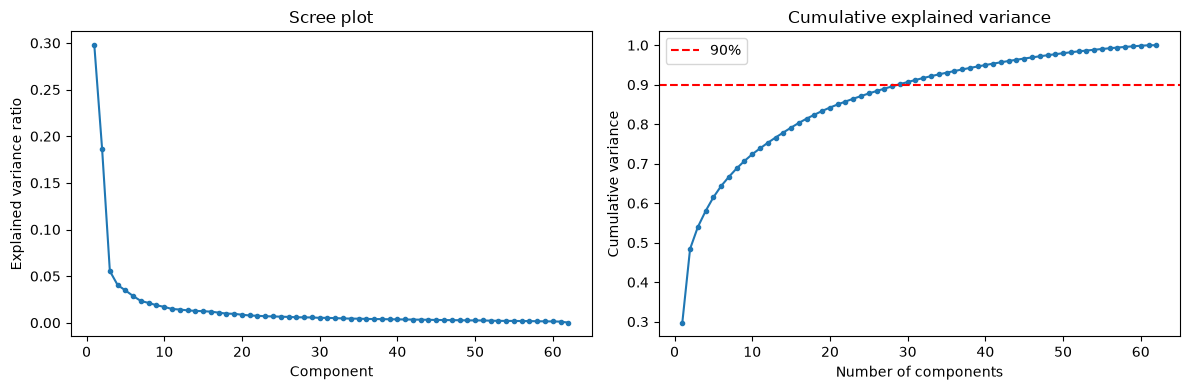

Least number of components for 90% variance:  29
Reduced shape: (12988, 29)


In [67]:
# 2. PCA Implementation and Smallest number of components 
    # Choice of selection : minimum number of components reaching 90% variance 

from sklearn.decomposition import PCA 

# Inspect the variance in current data: Implementing PCA with all components  
pca_full = PCA().fit(X) #learn all components 
var_ratio = pca_full.explained_variance_ratio_  #fraction of total variance sorted from most to leastimport
cum_var = np.cumsum(var_ratio)      #Answers, the variance it keep for keeping k components 
print (cum_var)


# Visualization 
# Scree plot : how much variance each component captures
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(range(1, len(var_ratio) + 1), var_ratio, marker='o', ms=3)
ax[0].set_title("Scree plot")
ax[0].set_xlabel("Component")
ax[0].set_ylabel("Explained variance ratio")

# cumulative variance plot
ax[1].plot(range(1, len(cum_var) + 1), cum_var, marker='o', ms=3)
ax[1].axhline(0.90, color='r', ls='--', label='90%')
ax[1].set_title("Cumulative explained variance")
ax[1].set_xlabel("Number of components")
ax[1].set_ylabel("Cumulative variance")
ax[1].legend()
plt.tight_layout()
plt.show()


# Smallest number of components 
    # Reaching 90% variance 
n_components = int(np.argmax(cum_var >= 0.90) + 1)
print('Least number of components for 90% variance: ', n_components)

# Final PCA 
pca = PCA(n_components=n_components, random_state=42)
X_pca = pca.fit_transform(X)
print("Reduced shape:", X_pca.shape)

In [78]:
# 3. Implementation of Distance Anamoly detction algorithm 
    # kNN Algorithm 

from pyod.models.knn import KNN
n = 20 # neighbors to look
knn = KNN(n_neighbors=n, method='largest', contamination=0.01)
knn.fit(X_pca)
scores = knn.decision_scores_   # gives higher value to points far from their neighbors 
print(scores)

# Anomalies score 
    # boxplot rule
q1, q3 = np.percentile(scores, [25, 75])
iqr = q3 - q1
threshold = q3 + 1.5 * iqr
is_anomaly = scores >= threshold 


print(f"Q1 = {q1:.3f}, Q3 = {q3:.3f}, IQR = {iqr:.3f}")
print(f"Threshold (Q3 + 1.5 *IQR) = {threshold:.3f}")
print(f"Anomalies flagged: {is_anomaly.sum()} ({is_anomaly.mean()*100:.2f}% of data)")



[5.16877952 4.45893184 2.76274647 ... 2.75869622 1.53143252 2.45332763]
Q1 = 2.519, Q3 = 3.962, IQR = 1.444
Threshold (Q3 + 1.5 *IQR) = 6.128
Anomalies flagged: 467 (3.60% of data)


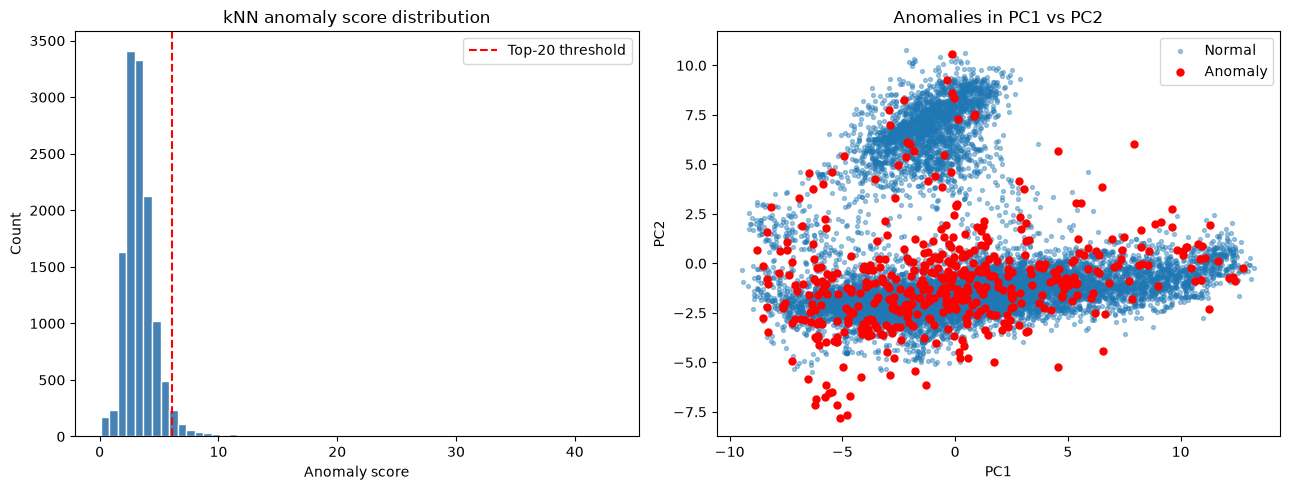

In [75]:
# 3. Visualization 

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# (a) Distribution of anomaly scores with the threshold
ax[0].hist(scores, bins=60, color='steelblue', edgecolor='white')
ax[0].axvline(threshold, color='red', ls='--', label=f'Top-{k} threshold')
ax[0].set_title("kNN anomaly score distribution")
ax[0].set_xlabel("Anomaly score")
ax[0].set_ylabel("Count")
ax[0].legend()

# (b) Anomalies in the space of the first two principal components
ax[1].scatter(X_pca[~is_anomaly, 0], X_pca[~is_anomaly, 1],
              s=8, alpha=0.4, label='Normal')
ax[1].scatter(X_pca[is_anomaly, 0], X_pca[is_anomaly, 1],
              s=25, color='red', label='Anomaly')
ax[1].set_title("Anomalies in PC1 vs PC2")
ax[1].set_xlabel("PC1")
ax[1].set_ylabel("PC2")
ax[1].legend()

plt.tight_layout()
plt.show()

<div class='alert alert-block alert-success' style="font-weight:bolder">
    
### Task 4: Reconstruction-Based Detection (3pts)

- Build an Autoencoder using PyTorch or TensorFlow and train it on the dataset.
- Compute reconstruction errors for the samples to identify the anomalies.
- Visualise the distribution of reconstruction errors and the anomalies identified.

 </div>

In [ ]:
## YOUR CODE HERE

<div class='alert alert-block alert-success' style="font-weight:bolder">
    
### Task 5: Isolation Forests (3pts)

- Randomly select d features for d = 5, 10, 20, … up to D in your dataset to create multiple subsets of feature spaces.
- For each subspace size 𝑑:
  - Train an Isolation Forest model on this subspace and compute anomaly scores for all samples.
  - Select the top-k anomalies (k should not be less than 50).
  - Repeat the above several times (e.g., 5–10 times) with different random feature subsets
- Compute the overlap of the top-k anomalies between different runs and average the overlaps to get one stability value per 𝑑.
- Plot the stability values against subspace size 𝑑
- Briefly report on your findings.

 </div>

In [ ]:
## YOUR CODE HERE

<div class='alert alert-block alert-success' style="font-weight:bolder">
    
### Task 6: Anomaly Similarity (1pts)

- In the previous exercises, we explored different methods of accomplishing anomaly detection in high-dimensional data: dimensionality reduction + distance-based anomaly detection, reconstruction-based, and IForest.
- How do the anomalies differ across the methods? Are there consistent patterns or disagreements?

 </div>

In [ ]:
## YOUR CODE HERE